# Official DehazeFormer-T: NHD Training and RESIDE / RESIDE-6K Testing

Kaggle-ready training and benchmarking notebook using the official DehazeFormer architecture. It keeps the existing NHD train/validation/test splits and RESIDE / RESIDE-6K paired evaluation workflow.

## Setup Dependencies


In [1]:
%%capture
!pip -q install scikit-image --root-user-action=ignore

## Imports and Warning Control


In [2]:
import os
# Set before CUDA/PyTorch initialization; restart the Kaggle kernel, then Run All.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import json
import random
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## Configuration
Update only the dataset paths if your Kaggle input slugs differ. The required folder layout is unchanged from `nhdv2`.


In [3]:
@dataclass
class CFG:
    ROOT: str = "/kaggle/input/datasets/mouryavardhanrathod/nhd-dataset-v1/NHD"
    INDEX_FILE: str = ""
    RESIDE_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD/test"
    RESIDE6K_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset/test"

    # DehazeFormer pads inputs automatically to a multiple of four. These are Kaggle-safe values.
    IMAGE_SIZE: int = 192
    BATCH_SIZE: int = 2
    ACCUM_STEPS: int = 4
    EPOCHS: int = 100
    LR: float = 2e-4
    WEIGHT_DECAY: float = 1e-4
    PATIENCE: int = 12
    NUM_WORKERS: int = 2
    SEED: int = 42
    OUT_DIR: str = "/kaggle/working/dehazeformer_nhd"
    SELECTED_STRATEGIES: tuple = ("uniform", "fog_bank", "perlin", "radial", "depth_dep")

cfg = CFG()
cfg.INDEX_FILE = os.path.join(cfg.ROOT, "dataset_index.json")
os.makedirs(cfg.OUT_DIR, exist_ok=True)
print("Output dir:", cfg.OUT_DIR)

Output dir: /kaggle/working/dehazeformer_nhd


## NHD Dataset Loader
NHD training/validation/test splits come from `dataset_index.json`. RESIDE and reside-6k use paired image folders for external evaluation.


In [4]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
image_transform = transforms.Compose([
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
])

def list_images(folder):
    if not folder or not os.path.isdir(folder):
        return []
    return sorted(
        os.path.join(root, name)
        for root, _, files in os.walk(folder)
        for name in files
        if name.lower().endswith(IMAGE_EXTENSIONS)
    )

def normalize_pair_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    for token in ("_hazy", "-hazy", " haze", "_gt", "-gt", "_clean", "-clean", "_clear", "-clear"):
        stem = stem.replace(token, "")
    return stem

def build_image_pairs_from_folders(hazy_dir, gt_dir):
    hazy_paths, gt_paths = list_images(hazy_dir), list_images(gt_dir)
    gt_by_stem = {normalize_pair_stem(path): path for path in gt_paths}
    pairs = [(hazy, gt_by_stem[normalize_pair_stem(hazy)]) for hazy in hazy_paths if normalize_pair_stem(hazy) in gt_by_stem]
    return pairs or (list(zip(hazy_paths, gt_paths)) if len(hazy_paths) == len(gt_paths) else [])

def find_paired_root(preferred, alternatives):
    for root in (preferred, *alternatives):
        if os.path.isdir(os.path.join(root, "hazy")) and os.path.isdir(os.path.join(root, "gt")):
            return root
    return None

class PairedDehazeDataset(Dataset):
    def __init__(self, pairs, dataset_name):
        self.pairs, self.dataset_name = pairs, dataset_name

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        hazy_path, gt_path = self.pairs[idx]
        hazy = Image.open(hazy_path).convert("RGB")
        gt = Image.open(gt_path).convert("RGB")
        return {
            "hazy": image_transform(hazy),
            "gt": image_transform(gt),
            "dataset": self.dataset_name,
            "img_id": os.path.basename(hazy_path),
        }

def build_nhd_pairs(split):
    if not os.path.isfile(cfg.INDEX_FILE):
        raise FileNotFoundError(f"NHD index not found: {cfg.INDEX_FILE}")
    with open(cfg.INDEX_FILE, "r") as f:
        metadata = json.load(f)
    pairs = []
    for item in metadata:
        if item.get("split") != split or item.get("strategy") not in cfg.SELECTED_STRATEGIES:
            continue
        hazy = os.path.join(cfg.ROOT, item["hazy_path"])
        gt = os.path.join(cfg.ROOT, item["gt_path"])
        if os.path.isfile(hazy) and os.path.isfile(gt):
            pairs.append((hazy, gt))
    return pairs

train_dataset = PairedDehazeDataset(build_nhd_pairs("train"), "NHD_dataset")
val_dataset = PairedDehazeDataset(build_nhd_pairs("val"), "NHD_dataset")
test_dataset = PairedDehazeDataset(build_nhd_pairs("test"), "NHD_dataset")
assert len(train_dataset) and len(val_dataset) and len(test_dataset), "NHD split is empty; check cfg.ROOT."

def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=cfg.BATCH_SIZE, shuffle=shuffle, num_workers=cfg.NUM_WORKERS, pin_memory=torch.cuda.is_available())

train_loader, val_loader, test_loader = make_loader(train_dataset, True), make_loader(val_dataset), make_loader(test_dataset)
print(f"NHD pairs — train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")


NHD pairs — train: 560, val: 70, test: 70


## Official DehazeFormer-T Architecture

This cell contains the official implementation from the authors’ MIT-licensed repository, adapted only to remove an unused `timm` import. The notebook instantiates **DehazeFormer-T**: [24, 48, 96, 48, 24] channels, depths [4, 4, 4, 2, 2], revised LayerNorm, depthwise-convolution attention, window attention, SKFusion skip aggregation, and the official (K 	imes x - B + x) reconstruction head.

To use larger official variants, change the final constructor from `dehazeformer_t()` to `dehazeformer_s()`, `dehazeformer_b()`, `dehazeformer_d()`, `dehazeformer_w()`, `dehazeformer_m()`, or `dehazeformer_l()`.

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np
from torch.nn.init import _calculate_fan_in_and_fan_out
from torch.nn.init import trunc_normal_


class RLN(nn.Module):
	r"""Revised LayerNorm"""
	def __init__(self, dim, eps=1e-5, detach_grad=False):
		super(RLN, self).__init__()
		self.eps = eps
		self.detach_grad = detach_grad

		self.weight = nn.Parameter(torch.ones((1, dim, 1, 1)))
		self.bias = nn.Parameter(torch.zeros((1, dim, 1, 1)))

		self.meta1 = nn.Conv2d(1, dim, 1)
		self.meta2 = nn.Conv2d(1, dim, 1)

		trunc_normal_(self.meta1.weight, std=.02)
		nn.init.constant_(self.meta1.bias, 1)

		trunc_normal_(self.meta2.weight, std=.02)
		nn.init.constant_(self.meta2.bias, 0)

	def forward(self, input):
		mean = torch.mean(input, dim=(1, 2, 3), keepdim=True)
		std = torch.sqrt((input - mean).pow(2).mean(dim=(1, 2, 3), keepdim=True) + self.eps)

		normalized_input = (input - mean) / std

		if self.detach_grad:
			rescale, rebias = self.meta1(std.detach()), self.meta2(mean.detach())
		else:
			rescale, rebias = self.meta1(std), self.meta2(mean)

		out = normalized_input * self.weight + self.bias
		return out, rescale, rebias


class Mlp(nn.Module):
	def __init__(self, network_depth, in_features, hidden_features=None, out_features=None):
		super().__init__()
		out_features = out_features or in_features
		hidden_features = hidden_features or in_features

		self.network_depth = network_depth

		self.mlp = nn.Sequential(
			nn.Conv2d(in_features, hidden_features, 1),
			nn.ReLU(True),
			nn.Conv2d(hidden_features, out_features, 1)
		)

		self.apply(self._init_weights)

	def _init_weights(self, m):
		if isinstance(m, nn.Conv2d):
			gain = (8 * self.network_depth) ** (-1/4)
			fan_in, fan_out = _calculate_fan_in_and_fan_out(m.weight)
			std = gain * math.sqrt(2.0 / float(fan_in + fan_out))
			trunc_normal_(m.weight, std=std)
			if m.bias is not None:
				nn.init.constant_(m.bias, 0)

	def forward(self, x):
		return self.mlp(x)


def window_partition(x, window_size):
	B, H, W, C = x.shape
	x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)
	windows = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size**2, C)
	return windows


def window_reverse(windows, window_size, H, W):
	B = int(windows.shape[0] / (H * W / window_size / window_size))
	x = windows.view(B, H // window_size, W // window_size, window_size, window_size, -1)
	x = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)
	return x


def get_relative_positions(window_size):
	coords_h = torch.arange(window_size)
	coords_w = torch.arange(window_size)

	coords = torch.stack(torch.meshgrid([coords_h, coords_w]))  # 2, Wh, Ww
	coords_flatten = torch.flatten(coords, 1)  # 2, Wh*Ww
	relative_positions = coords_flatten[:, :, None] - coords_flatten[:, None, :]  # 2, Wh*Ww, Wh*Ww

	relative_positions = relative_positions.permute(1, 2, 0).contiguous()  # Wh*Ww, Wh*Ww, 2
	relative_positions_log  = torch.sign(relative_positions) * torch.log(1. + relative_positions.abs())

	return relative_positions_log


class WindowAttention(nn.Module):
	def __init__(self, dim, window_size, num_heads):

		super().__init__()
		self.dim = dim
		self.window_size = window_size  # Wh, Ww
		self.num_heads = num_heads
		head_dim = dim // num_heads
		self.scale = head_dim ** -0.5

		relative_positions = get_relative_positions(self.window_size)
		self.register_buffer("relative_positions", relative_positions)
		self.meta = nn.Sequential(
			nn.Linear(2, 256, bias=True),
			nn.ReLU(True),
			nn.Linear(256, num_heads, bias=True)
		)

		self.softmax = nn.Softmax(dim=-1)

	def forward(self, qkv):
		B_, N, _ = qkv.shape

		qkv = qkv.reshape(B_, N, 3, self.num_heads, self.dim // self.num_heads).permute(2, 0, 3, 1, 4)

		q, k, v = qkv[0], qkv[1], qkv[2]  # make torchscript happy (cannot use tensor as tuple)

		q = q * self.scale
		attn = (q @ k.transpose(-2, -1))

		relative_position_bias = self.meta(self.relative_positions)
		relative_position_bias = relative_position_bias.permute(2, 0, 1).contiguous()  # nH, Wh*Ww, Wh*Ww
		attn = attn + relative_position_bias.unsqueeze(0)

		attn = self.softmax(attn)

		x = (attn @ v).transpose(1, 2).reshape(B_, N, self.dim)
		return x


class Attention(nn.Module):
	def __init__(self, network_depth, dim, num_heads, window_size, shift_size, use_attn=False, conv_type=None):
		super().__init__()
		self.dim = dim
		self.head_dim = int(dim // num_heads)
		self.num_heads = num_heads

		self.window_size = window_size
		self.shift_size = shift_size

		self.network_depth = network_depth
		self.use_attn = use_attn
		self.conv_type = conv_type

		if self.conv_type == 'Conv':
			self.conv = nn.Sequential(
				nn.Conv2d(dim, dim, kernel_size=3, padding=1, padding_mode='reflect'),
				nn.ReLU(True),
				nn.Conv2d(dim, dim, kernel_size=3, padding=1, padding_mode='reflect')
			)

		if self.conv_type == 'DWConv':
			self.conv = nn.Conv2d(dim, dim, kernel_size=5, padding=2, groups=dim, padding_mode='reflect')

		if self.conv_type == 'DWConv' or self.use_attn:
			self.V = nn.Conv2d(dim, dim, 1)
			self.proj = nn.Conv2d(dim, dim, 1)

		if self.use_attn:
			self.QK = nn.Conv2d(dim, dim * 2, 1)
			self.attn = WindowAttention(dim, window_size, num_heads)

		self.apply(self._init_weights)

	def _init_weights(self, m):
		if isinstance(m, nn.Conv2d):
			w_shape = m.weight.shape

			if w_shape[0] == self.dim * 2:	# QK
				fan_in, fan_out = _calculate_fan_in_and_fan_out(m.weight)
				std = math.sqrt(2.0 / float(fan_in + fan_out))
				trunc_normal_(m.weight, std=std)		
			else:
				gain = (8 * self.network_depth) ** (-1/4)
				fan_in, fan_out = _calculate_fan_in_and_fan_out(m.weight)
				std = gain * math.sqrt(2.0 / float(fan_in + fan_out))
				trunc_normal_(m.weight, std=std)

			if m.bias is not None:
				nn.init.constant_(m.bias, 0)

	def check_size(self, x, shift=False):
		_, _, h, w = x.size()
		mod_pad_h = (self.window_size - h % self.window_size) % self.window_size
		mod_pad_w = (self.window_size - w % self.window_size) % self.window_size

		if shift:
			x = F.pad(x, (self.shift_size, (self.window_size-self.shift_size+mod_pad_w) % self.window_size,
						  self.shift_size, (self.window_size-self.shift_size+mod_pad_h) % self.window_size), mode='reflect')
		else:
			x = F.pad(x, (0, mod_pad_w, 0, mod_pad_h), 'reflect')
		return x

	def forward(self, X):
		B, C, H, W = X.shape

		if self.conv_type == 'DWConv' or self.use_attn:
			V = self.V(X)

		if self.use_attn:
			QK = self.QK(X)
			QKV = torch.cat([QK, V], dim=1)

			# shift
			shifted_QKV = self.check_size(QKV, self.shift_size > 0)
			Ht, Wt = shifted_QKV.shape[2:]

			# partition windows
			shifted_QKV = shifted_QKV.permute(0, 2, 3, 1)
			qkv = window_partition(shifted_QKV, self.window_size)  # nW*B, window_size**2, C

			attn_windows = self.attn(qkv)

			# merge windows
			shifted_out = window_reverse(attn_windows, self.window_size, Ht, Wt)  # B H' W' C

			# reverse cyclic shift
			out = shifted_out[:, self.shift_size:(self.shift_size+H), self.shift_size:(self.shift_size+W), :]
			attn_out = out.permute(0, 3, 1, 2)

			if self.conv_type in ['Conv', 'DWConv']:
				conv_out = self.conv(V)
				out = self.proj(conv_out + attn_out)
			else:
				out = self.proj(attn_out)

		else:
			if self.conv_type == 'Conv':
				out = self.conv(X)				# no attention and use conv, no projection
			elif self.conv_type == 'DWConv':
				out = self.proj(self.conv(V))

		return out


class TransformerBlock(nn.Module):
	def __init__(self, network_depth, dim, num_heads, mlp_ratio=4.,
				 norm_layer=nn.LayerNorm, mlp_norm=False,
				 window_size=8, shift_size=0, use_attn=True, conv_type=None):
		super().__init__()
		self.use_attn = use_attn
		self.mlp_norm = mlp_norm

		self.norm1 = norm_layer(dim) if use_attn else nn.Identity()
		self.attn = Attention(network_depth, dim, num_heads=num_heads, window_size=window_size,
							  shift_size=shift_size, use_attn=use_attn, conv_type=conv_type)

		self.norm2 = norm_layer(dim) if use_attn and mlp_norm else nn.Identity()
		self.mlp = Mlp(network_depth, dim, hidden_features=int(dim * mlp_ratio))

	def forward(self, x):
		identity = x
		if self.use_attn: x, rescale, rebias = self.norm1(x)
		x = self.attn(x)
		if self.use_attn: x = x * rescale + rebias
		x = identity + x

		identity = x
		if self.use_attn and self.mlp_norm: x, rescale, rebias = self.norm2(x)
		x = self.mlp(x)
		if self.use_attn and self.mlp_norm: x = x * rescale + rebias
		x = identity + x
		return x


class BasicLayer(nn.Module):
	def __init__(self, network_depth, dim, depth, num_heads, mlp_ratio=4.,
				 norm_layer=nn.LayerNorm, window_size=8,
				 attn_ratio=0., attn_loc='last', conv_type=None):

		super().__init__()
		self.dim = dim
		self.depth = depth

		attn_depth = attn_ratio * depth

		if attn_loc == 'last':
			use_attns = [i >= depth-attn_depth for i in range(depth)]
		elif attn_loc == 'first':
			use_attns = [i < attn_depth for i in range(depth)]
		elif attn_loc == 'middle':
			use_attns = [i >= (depth-attn_depth)//2 and i < (depth+attn_depth)//2 for i in range(depth)]

		# build blocks
		self.blocks = nn.ModuleList([
			TransformerBlock(network_depth=network_depth,
							 dim=dim, 
							 num_heads=num_heads,
							 mlp_ratio=mlp_ratio,
							 norm_layer=norm_layer,
							 window_size=window_size,
							 shift_size=0 if (i % 2 == 0) else window_size // 2,
							 use_attn=use_attns[i], conv_type=conv_type)
			for i in range(depth)])

	def forward(self, x):
		for blk in self.blocks:
			x = blk(x)
		return x


class PatchEmbed(nn.Module):
	def __init__(self, patch_size=4, in_chans=3, embed_dim=96, kernel_size=None):
		super().__init__()
		self.in_chans = in_chans
		self.embed_dim = embed_dim

		if kernel_size is None:
			kernel_size = patch_size

		self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=kernel_size, stride=patch_size,
							  padding=(kernel_size-patch_size+1)//2, padding_mode='reflect')

	def forward(self, x):
		x = self.proj(x)
		return x


class PatchUnEmbed(nn.Module):
	def __init__(self, patch_size=4, out_chans=3, embed_dim=96, kernel_size=None):
		super().__init__()
		self.out_chans = out_chans
		self.embed_dim = embed_dim

		if kernel_size is None:
			kernel_size = 1

		self.proj = nn.Sequential(
			nn.Conv2d(embed_dim, out_chans*patch_size**2, kernel_size=kernel_size,
					  padding=kernel_size//2, padding_mode='reflect'),
			nn.PixelShuffle(patch_size)
		)

	def forward(self, x):
		x = self.proj(x)
		return x


class SKFusion(nn.Module):
	def __init__(self, dim, height=2, reduction=8):
		super(SKFusion, self).__init__()

		self.height = height
		d = max(int(dim/reduction), 4)

		self.avg_pool = nn.AdaptiveAvgPool2d(1)
		self.mlp = nn.Sequential(
			nn.Conv2d(dim, d, 1, bias=False), 
			nn.ReLU(),
			nn.Conv2d(d, dim*height, 1, bias=False)
		)

		self.softmax = nn.Softmax(dim=1)

	def forward(self, in_feats):
		B, C, H, W = in_feats[0].shape

		in_feats = torch.cat(in_feats, dim=1)
		in_feats = in_feats.view(B, self.height, C, H, W)

		feats_sum = torch.sum(in_feats, dim=1)
		attn = self.mlp(self.avg_pool(feats_sum))
		attn = self.softmax(attn.view(B, self.height, C, 1, 1))

		out = torch.sum(in_feats*attn, dim=1)
		return out      


class DehazeFormer(nn.Module):
	def __init__(self, in_chans=3, out_chans=4, window_size=8,
				 embed_dims=[24, 48, 96, 48, 24],
				 mlp_ratios=[2., 4., 4., 2., 2.],
				 depths=[16, 16, 16, 8, 8],
				 num_heads=[2, 4, 6, 1, 1],
				 attn_ratio=[1/4, 1/2, 3/4, 0, 0],
				 conv_type=['DWConv', 'DWConv', 'DWConv', 'DWConv', 'DWConv'],
				 norm_layer=[RLN, RLN, RLN, RLN, RLN]):
		super(DehazeFormer, self).__init__()

		# setting
		self.patch_size = 4
		self.window_size = window_size
		self.mlp_ratios = mlp_ratios

		# split image into non-overlapping patches
		self.patch_embed = PatchEmbed(
			patch_size=1, in_chans=in_chans, embed_dim=embed_dims[0], kernel_size=3)

		# backbone
		self.layer1 = BasicLayer(network_depth=sum(depths), dim=embed_dims[0], depth=depths[0],
					   			 num_heads=num_heads[0], mlp_ratio=mlp_ratios[0],
					   			 norm_layer=norm_layer[0], window_size=window_size,
					   			 attn_ratio=attn_ratio[0], attn_loc='last', conv_type=conv_type[0])

		self.patch_merge1 = PatchEmbed(
			patch_size=2, in_chans=embed_dims[0], embed_dim=embed_dims[1])

		self.skip1 = nn.Conv2d(embed_dims[0], embed_dims[0], 1)

		self.layer2 = BasicLayer(network_depth=sum(depths), dim=embed_dims[1], depth=depths[1],
								 num_heads=num_heads[1], mlp_ratio=mlp_ratios[1],
								 norm_layer=norm_layer[1], window_size=window_size,
								 attn_ratio=attn_ratio[1], attn_loc='last', conv_type=conv_type[1])

		self.patch_merge2 = PatchEmbed(
			patch_size=2, in_chans=embed_dims[1], embed_dim=embed_dims[2])

		self.skip2 = nn.Conv2d(embed_dims[1], embed_dims[1], 1)

		self.layer3 = BasicLayer(network_depth=sum(depths), dim=embed_dims[2], depth=depths[2],
								 num_heads=num_heads[2], mlp_ratio=mlp_ratios[2],
								 norm_layer=norm_layer[2], window_size=window_size,
								 attn_ratio=attn_ratio[2], attn_loc='last', conv_type=conv_type[2])

		self.patch_split1 = PatchUnEmbed(
			patch_size=2, out_chans=embed_dims[3], embed_dim=embed_dims[2])

		assert embed_dims[1] == embed_dims[3]
		self.fusion1 = SKFusion(embed_dims[3])

		self.layer4 = BasicLayer(network_depth=sum(depths), dim=embed_dims[3], depth=depths[3],
								 num_heads=num_heads[3], mlp_ratio=mlp_ratios[3],
								 norm_layer=norm_layer[3], window_size=window_size,
								 attn_ratio=attn_ratio[3], attn_loc='last', conv_type=conv_type[3])

		self.patch_split2 = PatchUnEmbed(
			patch_size=2, out_chans=embed_dims[4], embed_dim=embed_dims[3])

		assert embed_dims[0] == embed_dims[4]
		self.fusion2 = SKFusion(embed_dims[4])			

		self.layer5 = BasicLayer(network_depth=sum(depths), dim=embed_dims[4], depth=depths[4],
					   			 num_heads=num_heads[4], mlp_ratio=mlp_ratios[4],
					   			 norm_layer=norm_layer[4], window_size=window_size,
					   			 attn_ratio=attn_ratio[4], attn_loc='last', conv_type=conv_type[4])

		# merge non-overlapping patches into image
		self.patch_unembed = PatchUnEmbed(
			patch_size=1, out_chans=out_chans, embed_dim=embed_dims[4], kernel_size=3)


	def check_image_size(self, x):
		# NOTE: for I2I test
		_, _, h, w = x.size()
		mod_pad_h = (self.patch_size - h % self.patch_size) % self.patch_size
		mod_pad_w = (self.patch_size - w % self.patch_size) % self.patch_size
		x = F.pad(x, (0, mod_pad_w, 0, mod_pad_h), 'reflect')
		return x

	def forward_features(self, x):
		x = self.patch_embed(x)
		x = self.layer1(x)
		skip1 = x

		x = self.patch_merge1(x)
		x = self.layer2(x)
		skip2 = x

		x = self.patch_merge2(x)
		x = self.layer3(x)
		x = self.patch_split1(x)

		x = self.fusion1([x, self.skip2(skip2)]) + x
		x = self.layer4(x)
		x = self.patch_split2(x)

		x = self.fusion2([x, self.skip1(skip1)]) + x
		x = self.layer5(x)
		x = self.patch_unembed(x)
		return x

	def forward(self, x):
		H, W = x.shape[2:]
		x = self.check_image_size(x)

		feat = self.forward_features(x)
		K, B = torch.split(feat, (1, 3), dim=1)

		x = K * x - B + x
		x = x[:, :, :H, :W]
		return x


def dehazeformer_t():
    return DehazeFormer(
		embed_dims=[24, 48, 96, 48, 24],
		mlp_ratios=[2., 4., 4., 2., 2.],
		depths=[4, 4, 4, 2, 2],
		num_heads=[2, 4, 6, 1, 1],
		attn_ratio=[0, 1/2, 1, 0, 0],
		conv_type=['DWConv', 'DWConv', 'DWConv', 'DWConv', 'DWConv'])


def dehazeformer_s():
    return DehazeFormer(
		embed_dims=[24, 48, 96, 48, 24],
		mlp_ratios=[2., 4., 4., 2., 2.],
		depths=[8, 8, 8, 4, 4],
		num_heads=[2, 4, 6, 1, 1],
		attn_ratio=[1/4, 1/2, 3/4, 0, 0],
		conv_type=['DWConv', 'DWConv', 'DWConv', 'DWConv', 'DWConv'])


def dehazeformer_b():
    return DehazeFormer(
        embed_dims=[24, 48, 96, 48, 24],
		mlp_ratios=[2., 4., 4., 2., 2.],
		depths=[16, 16, 16, 8, 8],
		num_heads=[2, 4, 6, 1, 1],
		attn_ratio=[1/4, 1/2, 3/4, 0, 0],
		conv_type=['DWConv', 'DWConv', 'DWConv', 'DWConv', 'DWConv'])


def dehazeformer_d():
    return DehazeFormer(
        embed_dims=[24, 48, 96, 48, 24],
		mlp_ratios=[2., 4., 4., 2., 2.],
		depths=[32, 32, 32, 16, 16],
		num_heads=[2, 4, 6, 1, 1],
		attn_ratio=[1/4, 1/2, 3/4, 0, 0],
		conv_type=['DWConv', 'DWConv', 'DWConv', 'DWConv', 'DWConv'])


def dehazeformer_w():
    return DehazeFormer(
        embed_dims=[48, 96, 192, 96, 48],
		mlp_ratios=[2., 4., 4., 2., 2.],
		depths=[16, 16, 16, 8, 8],
		num_heads=[2, 4, 6, 1, 1],
		attn_ratio=[1/4, 1/2, 3/4, 0, 0],
		conv_type=['DWConv', 'DWConv', 'DWConv', 'DWConv', 'DWConv'])


def dehazeformer_m():
    return DehazeFormer(
		embed_dims=[24, 48, 96, 48, 24],
		mlp_ratios=[2., 4., 4., 2., 2.],
		depths=[12, 12, 12, 6, 6],
		num_heads=[2, 4, 6, 1, 1],
		attn_ratio=[1/4, 1/2, 3/4, 0, 0],
		conv_type=['Conv', 'Conv', 'Conv', 'Conv', 'Conv'])


def dehazeformer_l():
    return DehazeFormer(
		embed_dims=[48, 96, 192, 96, 48],
		mlp_ratios=[2., 4., 4., 2., 2.],
		depths=[16, 16, 16, 12, 12],
		num_heads=[2, 4, 6, 1, 1],
		attn_ratio=[1/4, 1/2, 3/4, 0, 0],
		conv_type=['Conv', 'Conv', 'Conv', 'Conv', 'Conv'])

# Official compact DehazeFormer-T variant, suitable for Kaggle training.
model = dehazeformer_t().to(device)
print(model)
print(f"DehazeFormer-T trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


DehazeFormer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), padding_mode=reflect)
  )
  (layer1): BasicLayer(
    (blocks): ModuleList(
      (0-3): 4 x TransformerBlock(
        (norm1): Identity()
        (attn): Attention(
          (conv): Conv2d(24, 24, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), groups=24, padding_mode=reflect)
          (V): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1))
          (proj): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1))
        )
        (norm2): Identity()
        (mlp): Mlp(
          (mlp): Sequential(
            (0): Conv2d(24, 48, kernel_size=(1, 1), stride=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(48, 24, kernel_size=(1, 1), stride=(1, 1))
          )
        )
      )
    )
  )
  (patch_merge1): PatchEmbed(
    (proj): Conv2d(24, 48, kernel_size=(2, 2), stride=(2, 2), padding_mode=reflect)
  )
  (skip1): Conv2d(24, 24, kernel_size=(1, 1), str

## End-to-End Joint Training
Train DehazeFormer directly on NHD paired hazy/clean images. The checkpoint with the highest validation PSNR is retained.


In [6]:
def charbonnier_loss(pred, target, eps=1e-3):
    return torch.mean(torch.sqrt((pred - target).pow(2) + eps * eps))

def batch_psnr(pred, target, eps=1e-8):
    mse = (pred - target).pow(2).flatten(1).mean(1).clamp_min(eps)
    return (10.0 * torch.log10(1.0 / mse)).mean()

def batch_ssim(pred, target, eps=1e-8):
    """Dependency-free global SSIM for training diagnostics (higher is better)."""
    x, y = pred.flatten(1), target.flatten(1)
    mux, muy = x.mean(1), y.mean(1)
    vx, vy = x.var(1, unbiased=False), y.var(1, unbiased=False)
    cov = ((x - mux[:, None]) * (y - muy[:, None])).mean(1)
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    score = ((2 * mux * muy + c1) * (2 * cov + c2)) / ((mux.square() + muy.square() + c1) * (vx + vy + c2) + eps)
    return score.mean()

def loss_fn(pred, target):
    return charbonnier_loss(pred, target)

def evaluate(model, loader):
    model.eval(); losses, psnrs, ssims, maes = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            hazy = batch['hazy'].to(device, non_blocking=True)
            gt = batch['gt'].to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=amp_enabled):
                pred = model(hazy); loss = loss_fn(pred, gt)
            pred, gt = pred.float(), gt.float()
            losses.append(loss.float().item()); psnrs.append(batch_psnr(pred, gt).item()); ssims.append(batch_ssim(pred, gt).item()); maes.append(F.l1_loss(pred, gt).item())
    return {'loss': float(np.mean(losses)), 'psnr': float(np.mean(psnrs)), 'ssim': float(np.mean(ssims)), 'mae': float(np.mean(maes))}

amp_enabled = device.type == 'cuda'
scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_psnr': [], 'val_ssim': [], 'val_mae': []}
best_psnr, bad_epochs = -float('inf'), 0
checkpoint_path = os.path.join(cfg.OUT_DIR, 'best_dehazeformer_nhd.pth')

for epoch in range(cfg.EPOCHS):
    model.train(); train_losses = []; optimizer.zero_grad(set_to_none=True)
    for step, batch in enumerate(tqdm(train_loader, desc=f'Epoch {epoch + 1}/{cfg.EPOCHS}', leave=False), start=1):
        hazy = batch['hazy'].to(device, non_blocking=True); gt = batch['gt'].to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=amp_enabled):
            loss = loss_fn(model(hazy), gt)
        scaler.scale(loss / cfg.ACCUM_STEPS).backward(); train_losses.append(loss.float().item())
        if step % cfg.ACCUM_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
    val = evaluate(model, val_loader); train_loss = float(np.mean(train_losses))
    history['epoch'].append(epoch + 1); history['train_loss'].append(train_loss); history['val_loss'].append(val['loss']); history['val_psnr'].append(val['psnr']); history['val_ssim'].append(val['ssim']); history['val_mae'].append(val['mae'])
    scheduler.step(val['psnr'])
    print(f"Epoch {epoch + 1:03d} | train={train_loss:.5f} | val_loss={val['loss']:.5f} | val_psnr={val['psnr']:.2f} | val_ssim={val['ssim']:.4f} | val_mae={val['mae']:.5f}")
    if val['psnr'] > best_psnr:
        best_psnr, bad_epochs = val['psnr'], 0; torch.save(model.state_dict(), checkpoint_path)
    else:
        bad_epochs += 1
        if bad_epochs >= cfg.PATIENCE:
            print('Early stopping.'); break

model.load_state_dict(torch.load(checkpoint_path, map_location=device))
print('Best validation PSNR:', f'{best_psnr:.2f}', '| checkpoint:', checkpoint_path)

Epoch 1/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 001 | train=0.14544 | val_loss=0.12418 | val_psnr=16.76 | val_ssim=0.6611 | val_mae=0.12416


Epoch 2/100:   0%|          | 0/280 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b0a7d543d80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b0a7d543d80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Epoch 002 | train=0.13138 | val_loss=0.11074 | val_psnr=17.43 | val_ssim=0.7443 | val_mae=0.11072


Epoch 3/100:   0%|          | 0/280 [00:00<?, ?it/s]

... (152 outputs left out)

Epoch 73/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 073 | train=0.03120 | val_loss=0.06469 | val_psnr=21.84 | val_ssim=0.9047 | val_mae=0.06466


Epoch 74/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 074 | train=0.03115 | val_loss=0.06475 | val_psnr=21.83 | val_ssim=0.9047 | val_mae=0.06472
Early stopping.
Best validation PSNR: 21.90 | checkpoint: /kaggle/working/dehazeformer_nhd/best_dehazeformer_nhd.pth


## Training Curves
Training Loss Curve, Validation Metric Curve, and MAE vs Epoch.


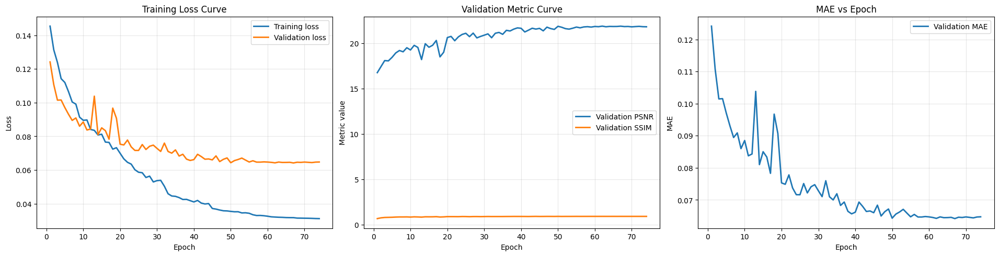

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
epochs = history["epoch"]
axes[0].plot(epochs, history["train_loss"], label="Training loss", linewidth=2)
axes[0].plot(epochs, history["val_loss"], label="Validation loss", linewidth=2)
axes[0].set(title="Training Loss Curve", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(epochs, history["val_psnr"], label="Validation PSNR", linewidth=2)
axes[1].plot(epochs, history["val_ssim"], label="Validation SSIM", linewidth=2)
axes[1].set(title="Validation Metric Curve", xlabel="Epoch", ylabel="Metric value")
axes[1].grid(alpha=.3); axes[1].legend()
axes[2].plot(epochs, history["val_mae"], label="Validation MAE", linewidth=2)
axes[2].set(title="MAE vs Epoch", xlabel="Epoch", ylabel="MAE")
axes[2].grid(alpha=.3); axes[2].legend()
plt.show()


## Test Protocol: NHD, RESIDE, and reside-6k
Every paired hazy image is dehazed and compared with its ground truth using PSNR, SSIM, MAE, and RMSE.


In [8]:
def dehaze_metrics(pred, gt):
    return {
        "PSNR": float(peak_signal_noise_ratio(gt, pred, data_range=1.0)),
        "SSIM": float(structural_similarity(gt, pred, channel_axis=-1, data_range=1.0)),
        "MAE": float(np.abs(pred.astype(np.float32) - gt.astype(np.float32)).mean()),
        "RMSE": float(np.sqrt(np.mean((pred.astype(np.float32) - gt.astype(np.float32)) ** 2))),
    }

def evaluate_dataset(model, dataset):
    records = []
    loader = make_loader(dataset)
    model.eval()
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Test {dataset.dataset_name}"):
            pred = model(batch["hazy"].to(device)).cpu()
            for i in range(pred.shape[0]):
                pred_np = pred[i].permute(1, 2, 0).numpy()
                gt_np = batch["gt"][i].permute(1, 2, 0).numpy()
                scores = dehaze_metrics(pred_np, gt_np)
                records.append({"dataset": dataset.dataset_name, "img_id": batch["img_id"][i], **scores})
    return pd.DataFrame(records)

reside_root = find_paired_root(cfg.RESIDE_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD",
    "/kaggle/input/reside-dataset-1/RESIDE_NHD/test",
    "/kaggle/input/reside/RESIDE_NHD/test",
])
reside6k_root = find_paired_root(cfg.RESIDE6K_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset",
    "/kaggle/input/reside-6k-dataset/test",
    "/kaggle/input/reside6k-dataset/test",
])

test_datasets = {"NHD_dataset": test_dataset}
if reside_root:
    reside_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside_root, "hazy"), os.path.join(reside_root, "gt")), "RESIDE")
    if len(reside_dataset): test_datasets["RESIDE"] = reside_dataset
else:
    print("RESIDE not found; attach the dataset or update cfg.RESIDE_ROOT.")
if reside6k_root:
    reside6k_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside6k_root, "hazy"), os.path.join(reside6k_root, "gt")), "reside-6k")
    if len(reside6k_dataset): test_datasets["reside-6k"] = reside6k_dataset
else:
    print("reside-6k not found; attach the dataset or update cfg.RESIDE6K_ROOT.")

per_image_results = pd.concat([evaluate_dataset(model, ds) for ds in test_datasets.values()], ignore_index=True)
dataset_summary = per_image_results.groupby("dataset", as_index=False).agg(Images=("img_id", "count"), PSNR=("PSNR", "mean"), SSIM=("SSIM", "mean"), MAE=("MAE", "mean"), RMSE=("RMSE", "mean")).sort_values("dataset")
display(dataset_summary.style.format({"PSNR": "{:.4f}", "SSIM": "{:.4f}", "MAE": "{:.6f}", "RMSE": "{:.6f}"}))
per_image_results.to_csv(os.path.join(cfg.OUT_DIR, "dehazeformer_per_image_results.csv"), index=False)
dataset_summary.to_csv(os.path.join(cfg.OUT_DIR, "dehazeformer_dataset_summary.csv"), index=False)


Test NHD_dataset:   0%|          | 0/35 [00:00<?, ?it/s]

Test RESIDE:   0%|          | 0/100 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b0a7d543d80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7b0a7d543d80>    self._shutdown_workers()

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
        self._shutdown_workers()if w.is_alive():

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
      if w.is_alive():   
   ^    ^^ ^ ^^^^^^^^^^^^^^^^^
^  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
^^    
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/lib/python

Test reside-6k:   0%|          | 0/500 [00:00<?, ?it/s]

,dataset,Images,PSNR,SSIM,MAE,RMSE
0,NHD_dataset,70,21.4230,0.8720,0.068077,0.090858
1,RESIDE,200,16.4085,0.7892,0.128288,0.165235
2,reside-6k,1000,18.0084,0.8072,0.101005,0.135157


## PSNR Comparison


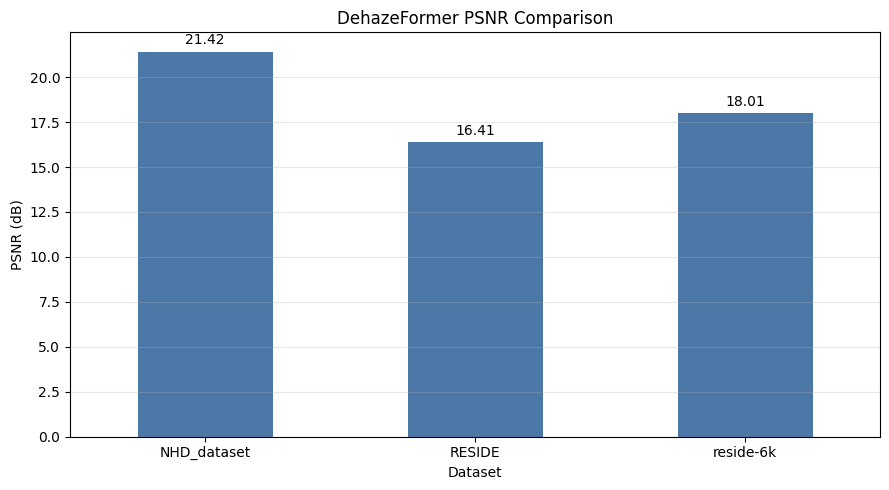

In [9]:
ax = dataset_summary.plot(x="dataset", y="PSNR", kind="bar", legend=False, figsize=(9, 5), color="#4C78A8")
ax.set(title="DehazeFormer PSNR Comparison", xlabel="Dataset", ylabel="PSNR (dB)")
ax.set_xticklabels(dataset_summary["dataset"], rotation=0)
ax.grid(axis="y", alpha=.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout(); plt.show()


## Subjective Visual Comparison
Show input haze, ground truth, DehazeFormer output, and an absolute-error map for every test dataset.


NHD_dataset


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.07117391..1.0456017].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.067451835..1.0375248].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.02939719..1.0480082].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.020435274..1.072001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.08988875..1.1632702].


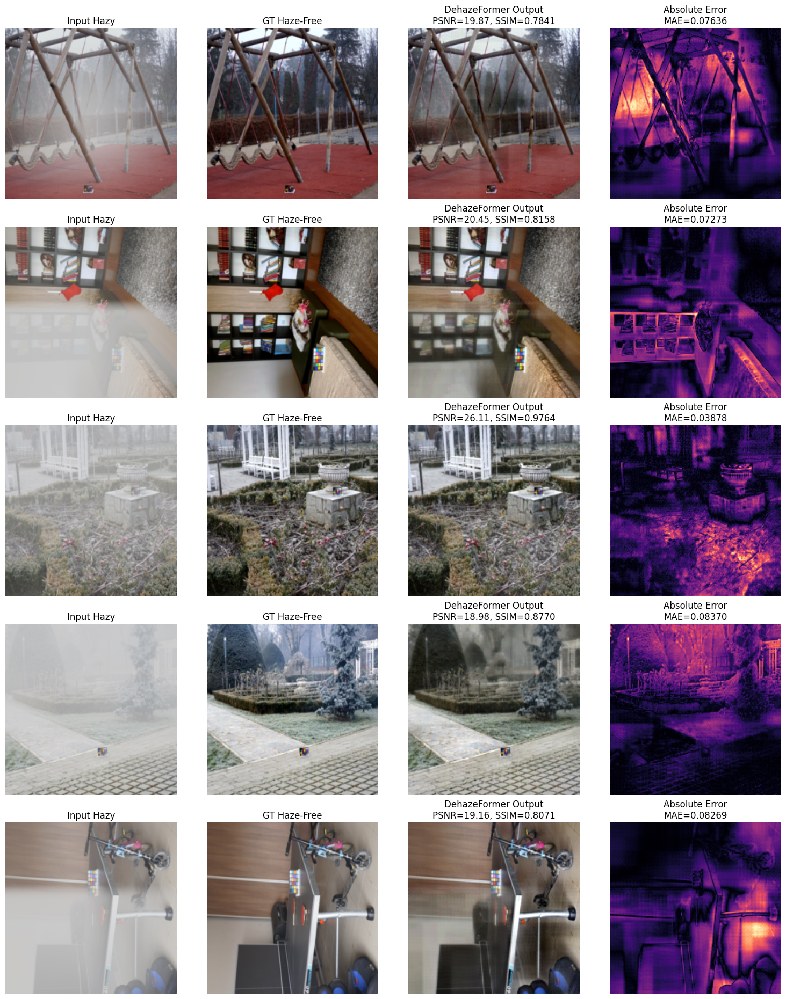

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.034342974..0.9767755].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.21818846..1.1500382].


RESIDE


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.10940668..1.0538511].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.15381584..0.9690981].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.026191145..1.0451031].


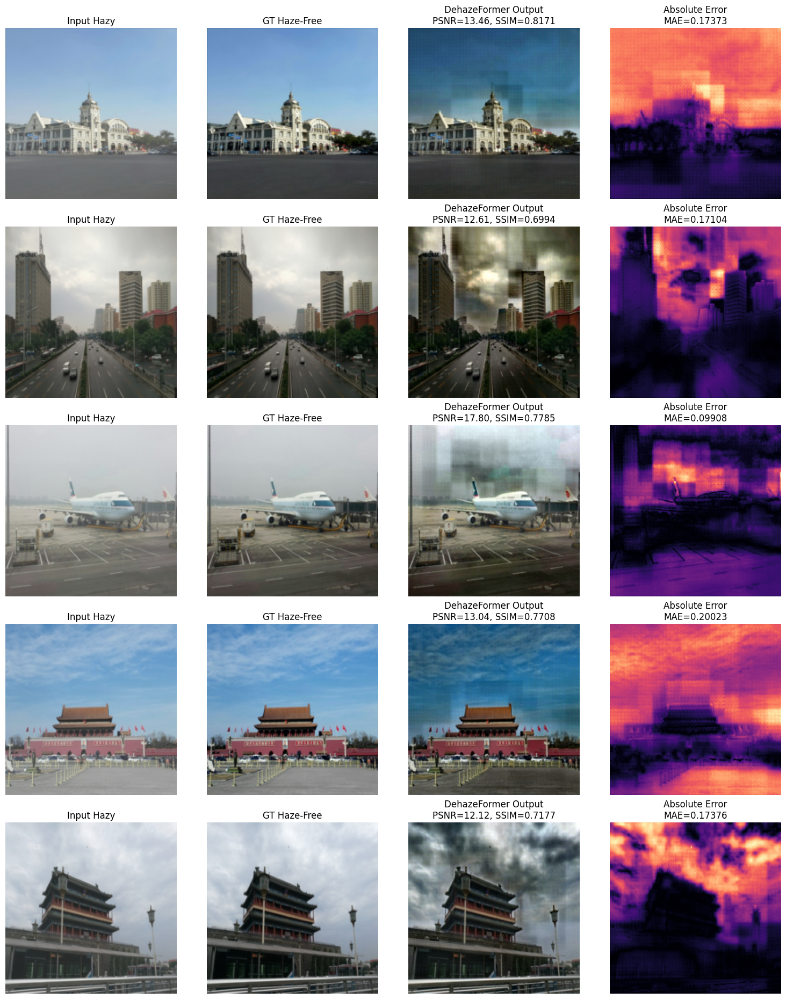

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.015472129..1.1624439].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.16352403..1.1466647].


reside-6k


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.020081088..1.0811634].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.14954916..1.1662831].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.14724877..1.1698976].


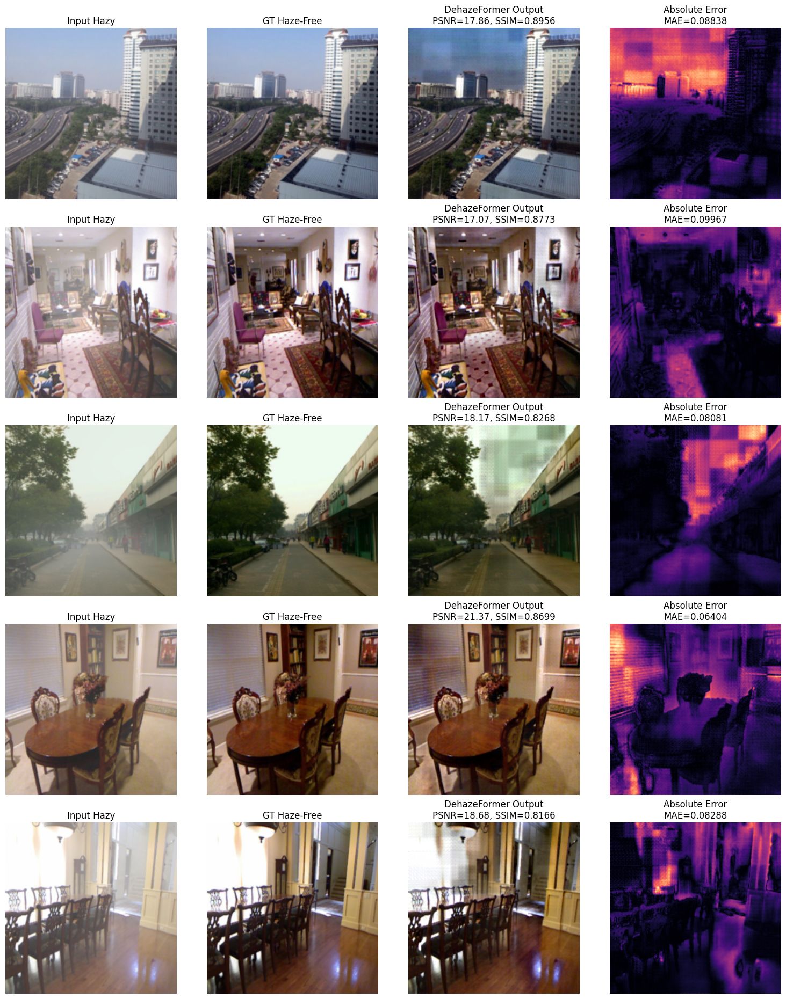

In [10]:
def show_subjective_comparison(model, dataset, n=5):
    model.eval()
    indices = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(len(indices), 4, figsize=(15, 3.7 * len(indices)), constrained_layout=True)
    if len(indices) == 1: axes = axes[None, :]
    with torch.no_grad():
        for row, idx in enumerate(indices):
            item = dataset[idx]
            hazy, gt = item["hazy"], item["gt"]
            pred = model(hazy.unsqueeze(0).to(device)).squeeze(0).cpu()
            hazy_np, gt_np, pred_np = [x.permute(1, 2, 0).numpy() for x in (hazy, gt, pred)]
            scores = dehaze_metrics(pred_np, gt_np)
            panels = [(hazy_np, "Input Hazy"), (gt_np, "GT Haze-Free"), (pred_np, f"DehazeFormer Output\nPSNR={scores['PSNR']:.2f}, SSIM={scores['SSIM']:.4f}"), (np.abs(pred_np - gt_np).mean(-1), f"Absolute Error\nMAE={scores['MAE']:.5f}")]
            for col, (image, title) in enumerate(panels):
                axes[row, col].imshow(image, cmap="magma" if col == 3 else None)
                axes[row, col].set_title(title); axes[row, col].axis("off")
    plt.show()

for name, dataset in test_datasets.items():
    print(name)
    show_subjective_comparison(model, dataset, n=5)


## Model Summary and Presentation Export


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.012798011..1.0516658].


Model: DehazeFormer
Trainable parameters: 687,404


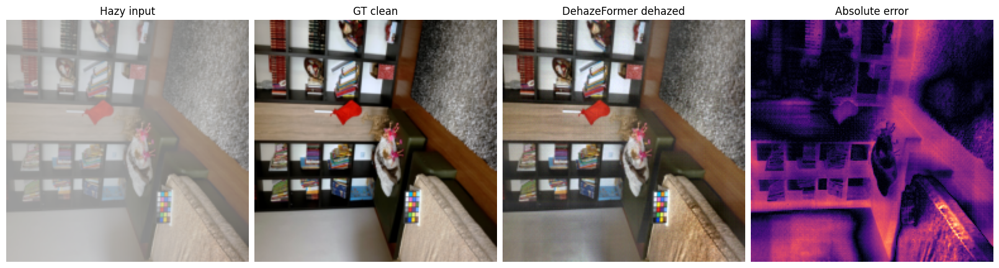

Saved: /kaggle/working/dehazeformer_nhd/dehazeformer_NHD_dataset_sample_000.png


,PSNR,SSIM,MAE,RMSE
0,19.894,0.8389,0.0799,0.1012


In [11]:
def export_presentation_sample(model, dataset, sample_index=0, output_dir=None):
    output_dir = output_dir or cfg.OUT_DIR
    os.makedirs(output_dir, exist_ok=True)
    item = dataset[sample_index]
    model.eval()
    with torch.no_grad():
        pred = model(item["hazy"].unsqueeze(0).to(device)).squeeze(0).cpu()
    hazy, gt, pred = [x.permute(1, 2, 0).numpy() for x in (item["hazy"], item["gt"], pred)]
    error = np.abs(pred - gt).mean(-1)
    scores = dehaze_metrics(pred, gt)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
    for ax, image, title in zip(axes, [hazy, gt, pred, error], ["Hazy input", "GT clean", "DehazeFormer dehazed", "Absolute error"]):
        ax.imshow(image, cmap="magma" if title == "Absolute error" else None)
        ax.set_title(title); ax.axis("off")
    path = os.path.join(output_dir, f"dehazeformer_{dataset.dataset_name}_sample_{sample_index:03d}.png")
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)
    display(pd.DataFrame([scores]).round(4))
    return path, scores

print(f"Model: {model.__class__.__name__}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
presentation_panel_path, presentation_sample_metrics = export_presentation_sample(model, test_dataset, sample_index=0)